# IFEval — instruction following (local)

IFEval gives the model 541 prompts that contain verifiable instructions ("write at least 300 words", "use no commas", "end with the phrase ...") and checks each response with code.

This notebook runs the benchmark **locally**, straight against the model's chat
endpoint — no EvalHub and no OpenShift. It is self-contained: all settings are in the
configuration cell below, and no job file is needed. It is the notebook equivalent of
the matching `run-*-local.sh` script.

**How it works:** [lm-evaluation-harness](https://github.com/EleutherAI/lm-evaluation-harness)
(`lm_eval`) is run through `uvx`, which fetches it on demand into a throwaway
environment. Questions are sent to the model's `/chat/completions` endpoint with the
model's chat template applied, and answers are scored locally.

**Requires:** [`uv`](https://docs.astral.sh/uv/) (for `uvx`) and network access to the
model endpoint.

## 1. Configuration

Everything you might want to change lives in this one cell.

In [1]:
import json, os, shutil, subprocess
from getpass import getpass
from pathlib import Path

# --- Model endpoint (from .env, or prompted for if there is no .env) ---
def load_env():
    """Read KEY=VALUE lines from a .env file into os.environ. Returns False if there is no file.

    Looks in the kernel's working directory, then ./notebooks (some Jupyter servers start the
    kernel in the repo's parent folder rather than next to the notebook)."""
    p = next((c for c in (Path(".env"), Path("notebooks/.env")) if c.is_file()), None)
    if p is None:
        return False
    for line in p.read_text().splitlines():
        line = line.strip()
        if line and not line.startswith("#") and "=" in line:
            key, value = line.split("=", 1)
            os.environ[key.strip()] = value.strip().strip("\"'")
    return True

if load_env():
    print("Loaded settings from .env")
    missing = [k for k in ("OPENAI_BASE_URL", "OPENAI_MODEL") if not os.environ.get(k)]
    if missing:
        raise SystemExit(f"Please set {', '.join(missing)} in .env (see dot_env.template)")
else:
    print("No .env file found (copy dot_env.template to .env to skip these prompts)")
    os.environ["OPENAI_BASE_URL"] = input("Model base URL (e.g. https://host/v1): ").strip()
    os.environ["OPENAI_MODEL"] = input("Model name: ").strip()
    os.environ["OPENAI_API_KEY"] = getpass("API key (leave blank if none): ")

MODEL_URL = os.environ["OPENAI_BASE_URL"].rstrip("/")  # OpenAI-compatible base URL
MODEL_NAME = os.environ["OPENAI_MODEL"]
MODEL_API_KEY = os.environ.get("OPENAI_API_KEY", "")


# --- Proxy (optional; set PROXY_URL in .env, leave empty for a direct connection) ---
def apply_proxy():
    """Export the proxy settings in the form each tool underneath reads them.

    uv, Python (requests / huggingface_hub / aiohttp) and npm read HTTP(S)_PROXY and NO_PROXY
    (upper or lower case); Node's built-in fetch needs NODE_USE_ENV_PROXY; npm also has its own
    npm_config_* names. CA_BUNDLE is for proxies that re-sign HTTPS traffic with a company CA."""
    url, no_proxy = os.environ.get("PROXY_URL", "").strip(), os.environ.get("NO_PROXY", "").strip()
    if url:
        # The model endpoint is sent through the proxy too, unless its host is listed in NO_PROXY.
        for k in ("HTTP_PROXY", "HTTPS_PROXY", "http_proxy", "https_proxy", "npm_config_proxy", "npm_config_https_proxy"):
            os.environ[k] = url
        os.environ["NODE_USE_ENV_PROXY"] = "1"
        if no_proxy:
            for k in ("NO_PROXY", "no_proxy", "npm_config_noproxy"):
                os.environ[k] = no_proxy
        print("Using proxy", url.split("@")[-1], "(NO_PROXY: " + (no_proxy or "none") + ")")
        # lm-eval 0.4.12 sends concurrent requests with aiohttp and never sets trust_env, so aiohttp
        # would ignore the variables above. This sitecustomize.py (loaded at start-up of the lm_eval
        # process via PYTHONPATH) makes every aiohttp.ClientSession trust them.
        patch_dir = Path(".eval-notebook-proxy-patch").resolve()
        patch_dir.mkdir(exist_ok=True)
        (patch_dir / "sitecustomize.py").write_text(
            "try:\n"
            "    import aiohttp\n"
            "    _init = aiohttp.ClientSession.__init__\n"
            "    def __init__(self, *a, **kw):\n"
            "        kw.setdefault('trust_env', True)\n"
            "        _init(self, *a, **kw)\n"
            "    aiohttp.ClientSession.__init__ = __init__\n"
            "except ImportError:\n"
            "    pass\n")
        os.environ["PYTHONPATH"] = os.pathsep.join(filter(None, [str(patch_dir), os.environ.get("PYTHONPATH")]))
    ca = os.environ.get("CA_BUNDLE", "").strip()
    if ca:
        ca = str(Path(ca).expanduser().resolve())
        for k in ("SSL_CERT_FILE", "REQUESTS_CA_BUNDLE", "CURL_CA_BUNDLE", "NODE_EXTRA_CA_CERTS"):
            os.environ[k] = ca
        print("Using CA bundle", ca)

apply_proxy()


# --- Benchmark ---
TASK = "ifeval"  # lm-eval task name
LM_EVAL_VERSION = "0.4.12"  # pinned so results are repeatable
LM_EVAL_EXTRAS = "api,ifeval"  # pip extras lm-eval needs for this task
PYPI_INDEX = "https://pypi.org/simple"  # package index used to install lm-eval, instead of any index set in your uv config
NUM_CONCURRENT = 8          # parallel requests to the model
THRESHOLD = 0.6  # minimum score to count as PASS
LIMIT = None                # e.g. 10 for a quick smoke test; None runs the full benchmark


Loaded settings from .env


## Helper

`run()` launches a command and streams its output into the notebook as it arrives, so you
can watch progress. It raises an error if the command exits non-zero.

In [2]:
def run(cmd, env=None):
    proc = subprocess.Popen(cmd, env={**os.environ, **(env or {})}, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True)
    for line in proc.stdout:
        print(line, end="")
    if proc.wait() != 0:
        raise RuntimeError(f"{cmd[0]} exited with {proc.returncode}")

## 2. Run the benchmark

Builds the `lm_eval` command and runs it. Completed requests are cached on disk, so if
the run dies partway (for example the gateway drops a connection), re-running this cell
resumes where it left off. The cache is deleted after a successful run so the next run
always gets fresh answers from the model.

In [3]:
OUTPUT = Path(f".eval-notebook-{TASK}")             # lm-eval writes results and samples here
CACHE = Path(f".eval-notebook-{TASK}-cache") / "requests"
CACHE.parent.mkdir(exist_ok=True)
shutil.rmtree(OUTPUT, ignore_errors=True)

cmd = ["uvx", "--default-index", PYPI_INDEX, "--python", "3.12", "--from", f"lm-eval[{LM_EVAL_EXTRAS}]=={LM_EVAL_VERSION}",
       "lm_eval", "--model", "local-chat-completions",
       "--model_args", f"model={MODEL_NAME},base_url={MODEL_URL.rstrip('/')}/chat/completions,"
                       f"num_concurrent={NUM_CONCURRENT},max_retries=5,tokenized_requests=False",
       "--tasks", TASK, "--apply_chat_template", "--log_samples",
       "--output_path", str(OUTPUT), "--use_cache", str(CACHE)]
if LIMIT:
    cmd += ["--limit", str(LIMIT)]

# Clear uv index overrides inherited from the environment so lm-eval installs from PYPI_INDEX.
uv_env = {k: "" for k in ("UV_INDEX", "UV_INDEX_URL", "UV_EXTRA_INDEX_URL", "UV_DEFAULT_INDEX")}
run(cmd, env={**uv_env, "OPENAI_API_KEY": MODEL_API_KEY or "not-required"})
shutil.rmtree(CACHE.parent, ignore_errors=True)

Installed 73 packages in 23.90s
Bytecode compiled 6548 files in 20.37s
2026-11-21:18:10:20 INFO     [config.evaluate_config:307] Using default fewshot_as_multiturn=True.
2026-11-21:18:11:12 INFO     [_cli.run:388] Selected Tasks: ['ifeval']
2026-11-21:18:11:12 INFO     [evaluator:214] Setting random seed to 0 | Setting numpy seed to 1234 | Setting torch manual seed to 1234 | Setting fewshot manual seed to 1234
2026-11-21:18:11:12 INFO     [evaluator:239] Initializing local-chat-completions model, with arguments: {'model': 'gemma-4', 'base_url': 'https://maas.apps.ocp.home.glroland.com/sandbox/gemma-4/v1/chat/completions', 'num_concurrent': 8, 'max_retries': 5, 'tokenized_requests': False}
2026-11-21:18:11:12 INFO     [models.api_models:179] Using max length 2048 - 1
2026-11-21:18:11:12 INFO     [models.api_models:200] Using tokenizer None
2026-11-21:18:11:12 INFO     [evaluator:278] Using cache at .eval-notebook-ifeval-cache/requests_rank0.db
2026-11-21:18:11:19 INFO     [evaluator_uti

## 3. Score and pass/fail

The headline score is `inst_level_strict_acc` — the fraction of individual instructions followed exactly. The loose and prompt-level variants are printed too. Per-question model answers are in the `.eval-notebook-<task>` folder (`samples_*.jsonl`) if you want to see what it got wrong.

In [4]:
results_file = next(OUTPUT.rglob("results_*.json"))
scores = json.loads(results_file.read_text())["results"][TASK]
print(json.dumps({k.split(",")[0]: v for k, v in scores.items()
                  if k.endswith(",none") and not k.startswith("alias")}, indent=2))

score = scores["inst_level_strict_acc,none"]
print("PASS" if score >= THRESHOLD else "FAIL", f"- inst_level_strict_acc {score:.3f} vs threshold {THRESHOLD}")

{
  "prompt_level_strict_acc": 0.8798521256931608,
  "prompt_level_strict_acc_stderr": 0.013991555826864732,
  "inst_level_strict_acc": 0.9172661870503597,
  "inst_level_strict_acc_stderr": "N/A",
  "prompt_level_loose_acc": 0.8983364140480592,
  "prompt_level_loose_acc_stderr": 0.013004849611340378,
  "inst_level_loose_acc": 0.9316546762589928,
  "inst_level_loose_acc_stderr": "N/A"
}
PASS - inst_level_strict_acc 0.917 vs threshold 0.6


## 4. Results dashboard

The headline score hides a lot. These charts show the same run four ways: strict vs. loose scoring, how difficulty grows with the number of instructions in a prompt, which of the instruction types the model is weakest at (with 95% confidence intervals), and the actual prompts it failed.

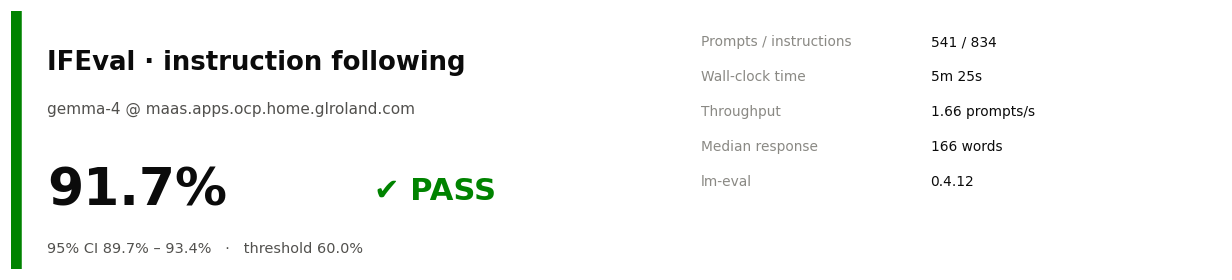

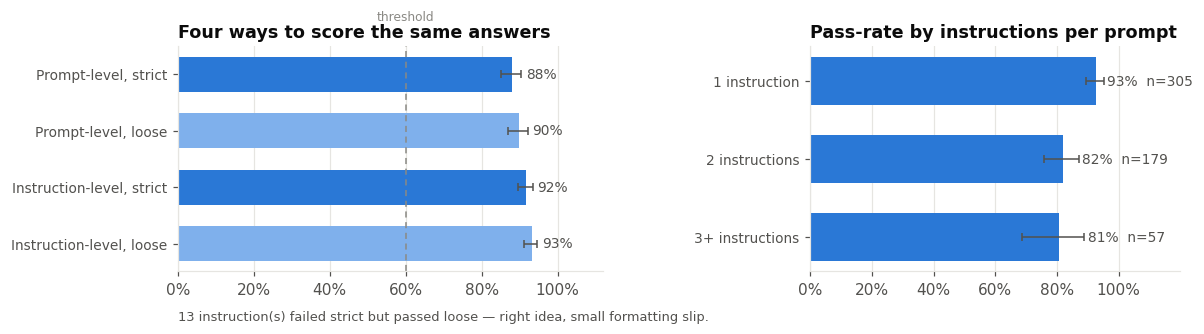

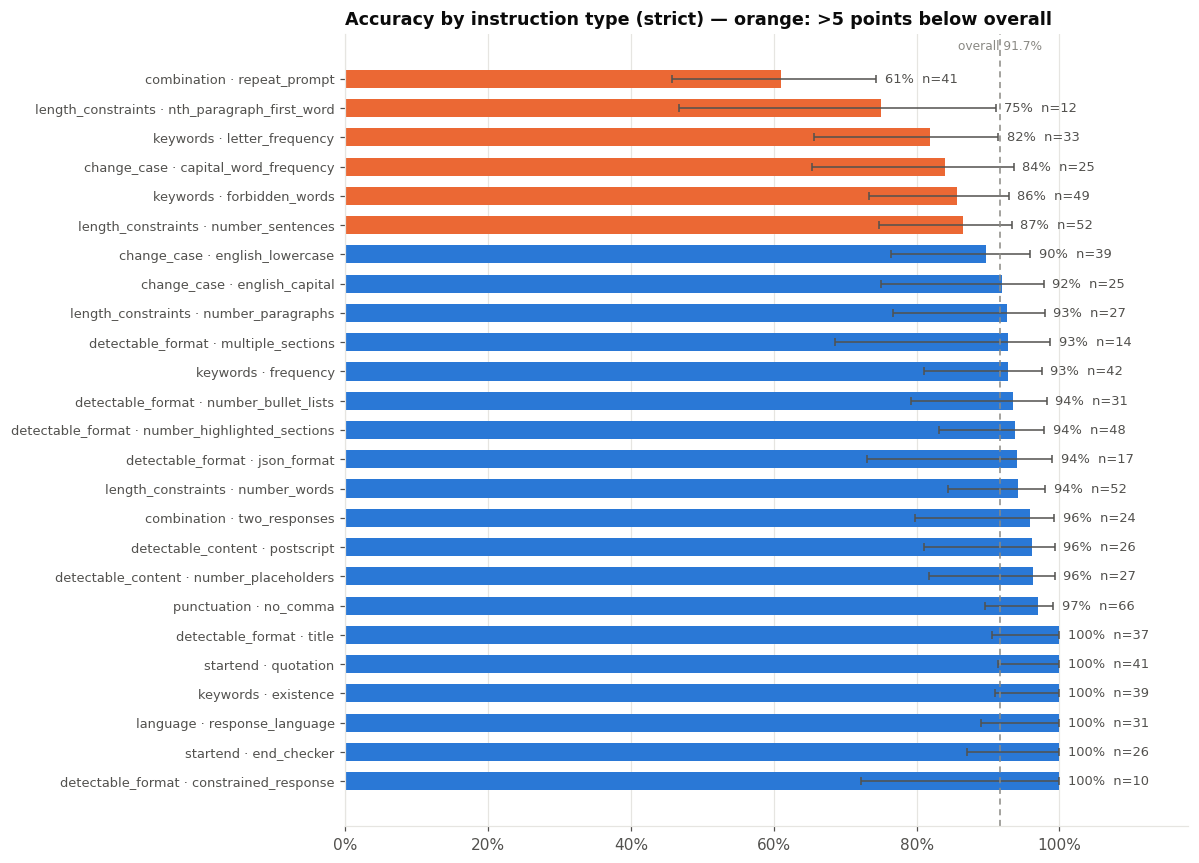

Prompts with at least one missed instruction: 65 of 541. The worst offenders:

  ✘ missed combination:repeat_prompt, punctuation:no_comma
      prompt:   Create a resume for a military officer who served in Iraq and was later hired by a private military contractor. Make sure to include a title that is wrapped in double an…
      response: Create a resume for a military officer who served in Iraq and was later hired by a private military contractor. Be sure to include a title that is wrapped in double angu…

  ✘ missed detectable_format:multiple_sections, length_constraints:number_sentences
      prompt:   Write a story about a man who is in love with a woman who has turrets. The story should be in at least 4 sections with each section starting with Section X (where X is 1…
      response: Section 1 The first time Elias saw Clara, he didn't notice the way her shoulder jerked or the way her head snapped to the side. He only noticed the way the sunlight caug…

  ✘ missed keywords:letter_f

In [5]:
import sys
from pathlib import Path
# eval_report.py sits next to the notebooks (the kernel may have started in the parent folder)
sys.path.insert(0, str(next(d for d in (Path("."), Path("notebooks")) if (d / "eval_report.py").is_file())))
from eval_report import report_ifeval

report_ifeval(OUTPUT, THRESHOLD)